# Solving the n-Queens Problem using Local Search

Student Name: Nhi

I have used the following AI tools: Claude (Anthropic)

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


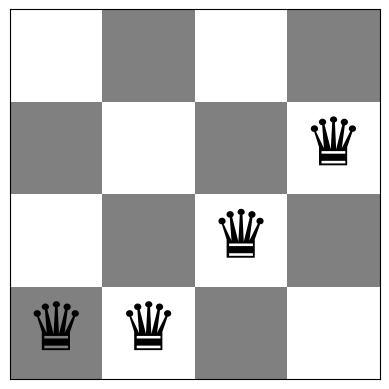

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [3]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


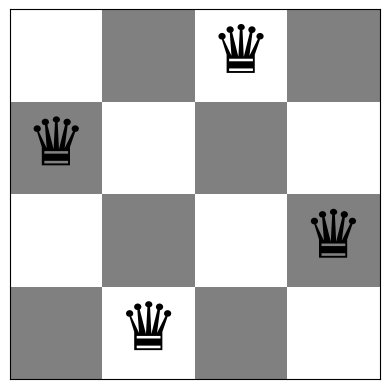

In [4]:
board = [1,3,0,2]
show_board(board)

# Bài 5. Biểu diễn bài toán n quân hậu

*Phần dưới đây bổ sung vào notebook đề; các ô gốc của đề được giữ nguyên.*

## Bài toán n quân hậu và cách biểu diễn
* **Mục tiêu:** đặt $n$ quân hậu lên bàn cờ $n \times n$ sao cho không có hai quân nào cùng hàng, cùng cột hoặc cùng đường chéo.
* **Không gian trạng thái:** mỗi cột có **đúng một** quân hậu. Một trạng thái ("board") là vector số nguyên $\mathbf{q} = (q_0, q_1, \dots, q_{n-1})$ với $q_i \in \{0, \dots, n-1\}$ là **chỉ số hàng** của quân hậu ở cột $i$. Ràng buộc "không cùng cột" được bảo đảm sẵn bởi cách biểu diễn nên không còn phải kiểm tra. Số trạng thái là $n^n$ (4⁴ = 256; 8⁸ = 16 777 216).
* **Hàm mục tiêu:** $h(\mathbf{q})$ = số **cặp** quân hậu cùng hàng hoặc cùng đường chéo.

### Định nghĩa hàm mục tiêu $h$

Hai quân ở cột $i < j$ (hàng $q_i$, $q_j$) **tấn công nhau** khi

$$ q_i = q_j \quad (\text{cùng hàng}) \qquad \text{hoặc} \qquad |q_i - q_j| = j - i \quad (\text{cùng đường chéo}). $$

(Cùng cột thì không thể xảy ra vì mỗi cột chỉ có một quân.) Khi đó

$$ h(\mathbf{q}) = \Big|\{(i, j) : 0 \le i < j \le n-1,\; q_i = q_j \ \text{hoặc}\ |q_i - q_j| = j - i\}\Big| = \sum_{i<j} \mathbb{1}\big[q_i = q_j \ \lor\ |q_i - q_j| = j - i\big]. $$

* Giá trị nhỏ nhất là $0$, lớn nhất là $\binom{n}{2}$ (mọi quân trên cùng một hàng hoặc một đường chéo).
* Một cặp có thể **không** đồng thời cùng hàng và cùng đường chéo (hai điều kiện loại trừ nhau khi $i \neq j$: cùng hàng thì $|q_i - q_j| = 0 \neq j - i$), nên không bị đếm trùng.
* **$h(\mathbf{q}) = 0 \iff$ không có cặp quân hậu nào tấn công nhau.** Chứng minh: $h$ là một tổng các số hạng $\mathbb{1}[\cdot] \in \{0, 1\}$ không âm, nên $h = 0$ khi và chỉ khi mọi số hạng bằng 0, tức là không có cặp $(i, j)$ nào thỏa điều kiện tấn công. Ta cũng kiểm tra bằng thực nghiệm ở bên dưới.

Hàm `conflicts(board)` của notebook không duyệt $O(n^2)$ cặp mà **đếm số quân trên từng hàng / từng đường chéo** rồi cộng $\binom{c}{2}$ cho mỗi nhóm có $c$ quân: một nhóm $c$ quân cùng đường thì có $\binom{c}{2}$ cặp tấn công nhau. Độ phức tạp $O(n)$. Hai cách tính phải cho cùng giá trị — ta sẽ kiểm chứng.

In [5]:
import itertools, json, os, time
os.makedirs('figs', exist_ok=True); os.makedirs('results', exist_ok=True)
RES = {}

## 5.2 Cài đặt $h$ theo định nghĩa (đếm từng cặp) và kiểm chứng với `conflicts()`
Hai hàm dưới đây **không dùng chung mã** với `conflicts()`, nên dùng làm "đáp án đối chứng".

In [6]:
def attacking_pairs(board):
    """Liệt kê các cặp (i, j), i < j, tấn công nhau - theo đúng định nghĩa."""
    n = len(board)
    return [(i, j) for i in range(n) for j in range(i + 1, n)
            if board[i] == board[j] or abs(board[i] - board[j]) == j - i]

def h(board):
    """Hàm mục tiêu theo định nghĩa: số cặp quân hậu cùng hàng hoặc cùng đường chéo (O(n^2))."""
    return len(attacking_pairs(board))

# ví dụ minh hoạ
for b in ([1, 3, 0, 2], [0, 1, 2, 3], [0, 0, 0, 0], [0, 2, 1, 3]):
    print(f"board = {b}: h = {h(b)}, conflicts = {conflicts(b)}, cặp tấn công = {attacking_pairs(b)}")

board = [1, 3, 0, 2]: h = 0, conflicts = 0, cặp tấn công = []
board = [0, 1, 2, 3]: h = 6, conflicts = 6, cặp tấn công = [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)]
board = [0, 0, 0, 0]: h = 6, conflicts = 6, cặp tấn công = [(0, 1), (0, 2), (0, 3), (1, 2), (1, 3), (2, 3)]
board = [0, 2, 1, 3]: h = 2, conflicts = 2, cặp tấn công = [(0, 3), (1, 2)]


**Kiểm chứng đầy đủ (exhaustive).** Với $n = 4, 5, 6$ ta duyệt **toàn bộ** $n^n$ bàn cờ; với $n = 8$ duyệt toàn bộ $8^8 = 16\,777\,216$ bàn cờ bằng numpy (tính $h$ theo định nghĩa theo từng cặp cột, vector hóa). Với mỗi bàn cờ kiểm tra (i) `conflicts(board) == h(board)` và (ii) `h == 0` khi và chỉ khi danh sách cặp tấn công rỗng; đồng thời đếm số bàn cờ có $h = 0$ (số nghiệm).

In [7]:
# --- n = 4, 5, 6: duyệt toàn bộ n^n bàn cờ bằng Python thuần ---
summary = []
for nn in (4, 5, 6):
    total = zero = 0
    for b in itertools.product(range(nn), repeat=nn):
        total += 1
        pairs = attacking_pairs(b)
        hv = conflicts(b)
        assert hv == len(pairs)                    # (i) hai cách tính trùng nhau
        assert (hv == 0) == (len(pairs) == 0)      # (ii) h = 0  <=>  không có cặp tấn công
        zero += (hv == 0)
    summary.append({'n': nn, 'boards': total, 'solutions': zero})
    print(f"n = {nn}: duyệt {total:,} bàn cờ, số bàn cờ h = 0: {zero}  -> kiểm chứng đạt")

# --- n = 8: duyệt toàn bộ 8^8 bàn cờ bằng numpy ---
def exhaustive_numpy(nn, chunk_first=1):
    """Duyệt mọi bàn cờ; cố định q0 = a (a = 0..n-1) để chia nhỏ bộ nhớ. Trả về (tổng, số h=0, histogram của h)."""
    total = 0; zero = 0; hist = {}
    rest = np.array(list(itertools.product(range(nn), repeat=nn - 1)), dtype=np.int8)   # n^(n-1) x (n-1)
    for a in range(nn):
        Q = np.concatenate([np.full((rest.shape[0], 1), a, dtype=np.int8), rest], axis=1)
        H = np.zeros(Q.shape[0], dtype=np.int16)
        for i in range(nn):
            for j in range(i + 1, nn):
                d = np.abs(Q[:, i].astype(np.int16) - Q[:, j].astype(np.int16))
                H += ((d == 0) | (d == j - i))
        total += Q.shape[0]; zero += int((H == 0).sum())
        vals, cnts = np.unique(H, return_counts=True)
        for v, c in zip(vals, cnts): hist[int(v)] = hist.get(int(v), 0) + int(c)
    return total, zero, hist

t0 = time.perf_counter()
tot8, zero8, hist8 = exhaustive_numpy(8)
print(f"n = 8: duyệt {tot8:,} bàn cờ, số bàn cờ h = 0: {zero8}  ({time.perf_counter() - t0:.1f} s)")
summary.append({'n': 8, 'boards': tot8, 'solutions': zero8})
RES['exhaustive'] = summary
RES['hist8_exact'] = hist8

n = 4: duyệt 256 bàn cờ, số bàn cờ h = 0: 2  -> kiểm chứng đạt
n = 5: duyệt 3,125 bàn cờ, số bàn cờ h = 0: 10  -> kiểm chứng đạt
n = 6: duyệt 46,656 bàn cờ, số bàn cờ h = 0: 4  -> kiểm chứng đạt
n = 8: duyệt 16,777,216 bàn cờ, số bàn cờ h = 0: 92  (5.2 s)


In [8]:
# đối chứng ngẫu nhiên: conflicts() == h() trên 20 000 bàn cờ n = 8 và 5 000 bàn cờ n = 12
rng_ok = 0
for nn, trials in ((8, 20000), (12, 5000)):
    for _ in range(trials):
        b = random_board(nn)
        assert conflicts(b) == h(b)
        assert (conflicts(b) == 0) == (len(attacking_pairs(b)) == 0)
        rng_ok += 1
print(f"{rng_ok:,} bàn cờ ngẫu nhiên: conflicts() == h() và (h=0 <=> không có cặp tấn công) đều đúng")

25,000 bàn cờ ngẫu nhiên: conflicts() == h() và (h=0 <=> không có cặp tấn công) đều đúng


**Kết luận kiểm chứng.** Với $n = 4, 5, 6, 8$ mọi bàn cờ đều thỏa `conflicts(board) == h(board)` và $h = 0 \iff$ không có cặp tấn công. Số nghiệm (bàn cờ có $h = 0$, mỗi cột một quân) là: $n = 4$: 2, $n = 5$: 10, $n = 6$: 4, $n = 8$: 92 — đúng bằng số cách đặt n quân hậu không tấn công nhau đã biết, nghĩa là biểu diễn "mỗi cột một quân" không bỏ sót nghiệm nào (vì ở nghiệm thật, mỗi cột bắt buộc có đúng một quân).

## 5.3 Bàn cờ n = 4 và n = 8: hiển thị cùng $h$
Hàm vẽ dưới đây vẽ bàn cờ, gạch nối đỏ giữa các cặp quân tấn công nhau, và ghi $h$ trong tiêu đề.

n = 4 ngẫu nhiên                         board = [3, 3, 2, 1]  h = 4  số cặp tấn công = 4
n = 4 nghiệm [1, 3, 0, 2]                board = [1, 3, 0, 2]  h = 0  số cặp tấn công = 0
n = 8 ngẫu nhiên                         board = [4, 4, 0, 1, 7, 1, 7, 1]  h = 8  số cặp tấn công = 8
n = 8 nghiệm [0, 4, 7, 5, 2, 6, 1, 3]    board = [0, 4, 7, 5, 2, 6, 1, 3]  h = 0  số cặp tấn công = 0


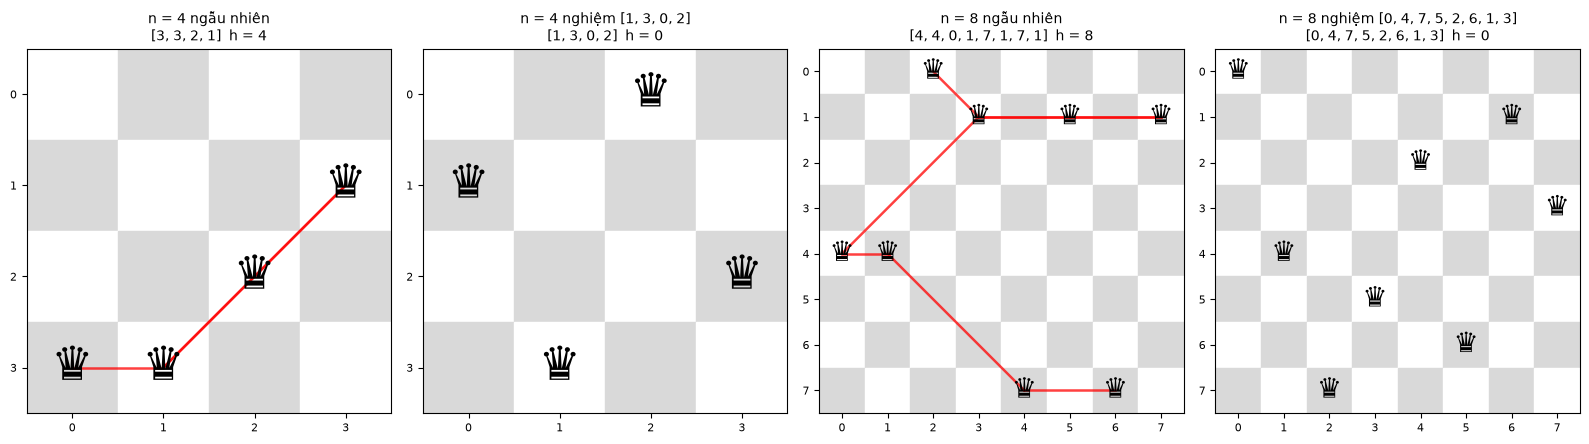

In [9]:
def draw_board(ax, board, title="", fontsize=None):
    n = len(board)
    fs = fontsize or {4: 34, 8: 20}.get(n, max(8, int(160 / n)))
    for i in range(n):
        for j in range(n):
            ax.add_patch(plt.Rectangle((j - .5, i - .5), 1, 1, color='#d9d9d9' if (i + j) % 2 else 'white'))
    for (i, j) in attacking_pairs(board):                       # đường nối các cặp tấn công
        ax.plot([i, j], [board[i], board[j]], color='red', lw=1.8, alpha=.75, zorder=2)
    for c in range(n):
        ax.text(c, board[c], u"\u265B", fontsize=fs, ha='center', va='center', zorder=3)
    ax.set_xlim(-.5, n - .5); ax.set_ylim(n - .5, -.5); ax.set_aspect('equal')
    ax.set_xticks(range(n)); ax.set_yticks(range(n)); ax.tick_params(labelsize=8)
    ax.set_title(title, fontsize=10)

np.random.seed(1234)
b4 = random_board(4);   b8 = random_board(8)
sol4 = [1, 3, 0, 2]
sol8 = [0, 4, 7, 5, 2, 6, 1, 3]        # một nghiệm quen thuộc của bài toán 8 quân hậu
boards = [(b4, "n = 4 ngẫu nhiên"), (sol4, "n = 4 nghiệm [1, 3, 0, 2]"),
          (b8, "n = 8 ngẫu nhiên"), (sol8, "n = 8 nghiệm [0, 4, 7, 5, 2, 6, 1, 3]")]
fig, axs = plt.subplots(1, 4, figsize=(16, 4.4))
for ax, (b, t) in zip(axs, boards):
    draw_board(ax, b, f"{t}\n{list(map(int, b))}  h = {conflicts(b)}")
    print(f"{t:40s} board = {list(map(int, b))}  h = {conflicts(b)}  số cặp tấn công = {len(attacking_pairs(b))}")
plt.tight_layout(); plt.savefig('figs/fig5_ban_co.png', dpi=150, bbox_inches='tight'); plt.show()
assert conflicts(sol4) == 0 and conflicts(sol8) == 0

Hiển thị bằng `show_board()` của notebook gốc cho hai bàn cờ ngẫu nhiên (n = 4 và n = 8) và nghiệm n = 8:

Board with 4 conflicts.


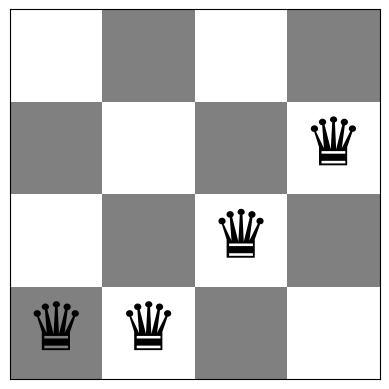

Board with 8 conflicts.


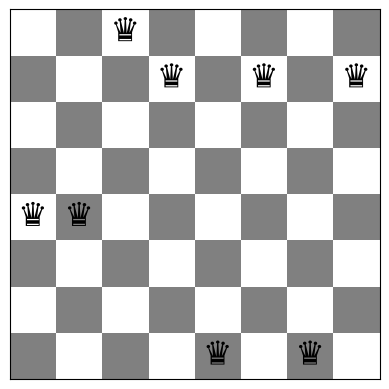

Board with 0 conflicts.


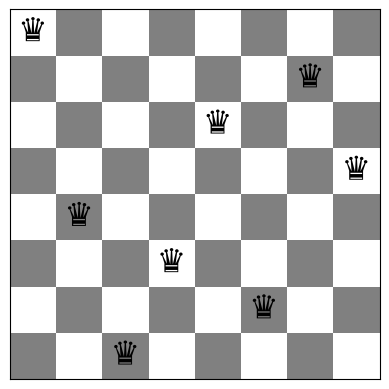

In [10]:
show_board(b4)
show_board(b8, fontsize=24)
show_board(sol8, fontsize=24)

## 5.4 Phân bố của $h$ trên bàn cờ ngẫu nhiên
Để hiểu độ khó của việc tìm nghiệm bằng cách đoán ngẫu nhiên: với $n = 8$, ta đã đếm chính xác phân bố của $h$ trên **toàn bộ** $8^8$ bàn cờ ở trên (`hist8`); với $n = 4$ phân bố trên toàn bộ 256 bàn cờ.

n = 4: tổng 256 bàn cờ; h trung bình = 3.250; h nhỏ nhất = 0; h lớn nhất = 6; tỉ lệ h = 0: 2/256 = 7.812e-03
n = 8: tổng 16,777,216 bàn cờ; h trung bình = 7.875; h nhỏ nhất = 0; h lớn nhất = 28; tỉ lệ h = 0: 92/16,777,216 = 5.484e-06


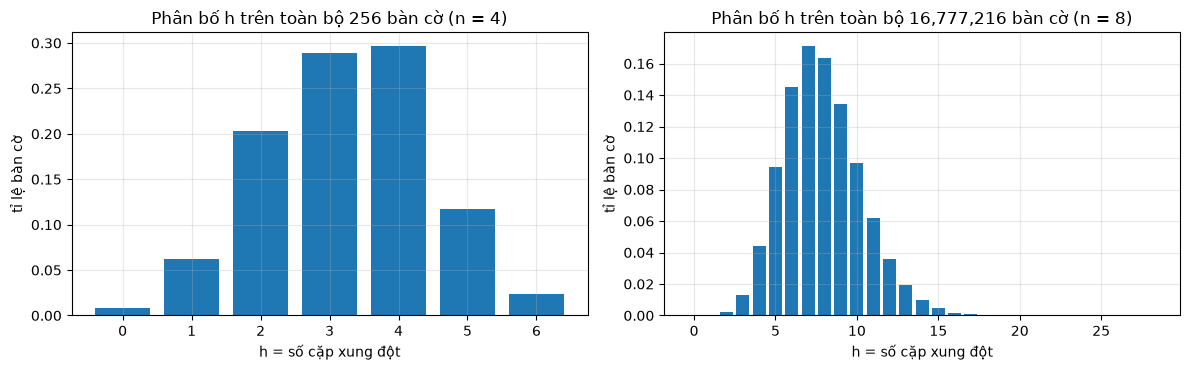

n = 4: số láng giềng của mỗi bàn cờ = n(n-1) = 12
n = 8: số láng giềng của mỗi bàn cờ = n(n-1) = 56


In [11]:
hist4 = {}
for b in itertools.product(range(4), repeat=4):
    v = conflicts(b); hist4[v] = hist4.get(v, 0) + 1

def stats(hist):
    tot = sum(hist.values())
    mean = sum(k * v for k, v in hist.items()) / tot
    return tot, mean

for nn, hist in ((4, hist4), (8, hist8)):
    tot, mean = stats(hist)
    print(f"n = {nn}: tổng {tot:,} bàn cờ; h trung bình = {mean:.3f}; h nhỏ nhất = {min(hist)}; h lớn nhất = {max(hist)}; "
          f"tỉ lệ h = 0: {hist[0]}/{tot:,} = {hist[0]/tot:.3e}")
RES['hist4'] = {int(k): int(v) for k, v in hist4.items()}
RES['stats'] = {'n4_mean': stats(hist4)[1], 'n8_mean': stats(hist8)[1],
                'n4_p0': hist4[0] / 256, 'n8_p0': hist8[0] / 8**8}

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (nn, hist) in zip(axs, ((4, hist4), (8, hist8))):
    ks = sorted(hist); tot = sum(hist.values())
    ax.bar(ks, [hist[k] / tot for k in ks], color='tab:blue')
    ax.set_title(f"Phân bố h trên toàn bộ {tot:,} bàn cờ (n = {nn})")
    ax.set_xlabel("h = số cặp xung đột"); ax.set_ylabel("tỉ lệ bàn cờ"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig('figs/fig6_phan_bo_h.png', dpi=150, bbox_inches='tight'); plt.show()

# số láng giềng của một trạng thái theo toán tử "đổi hàng của một quân"
for nn in (4, 8): print(f"n = {nn}: số láng giềng của mỗi bàn cờ = n(n-1) = {nn*(nn-1)}")
json.dump(RES, open('results/nq_results.json', 'w'), indent=1)

## 5.5 Nhận xét

* Mỗi cột đúng một quân hậu nên không gian trạng thái giảm từ $\binom{n^2}{n}$ xuống $n^n$ và ràng buộc "không cùng cột" luôn thỏa. Chỉ còn hai họ ràng buộc nhị phân: cùng hàng và cùng đường chéo.
* $h$ là một hàm mục tiêu cần **cực tiểu hóa** với giá trị tối ưu đã biết là 0; nghiệm = bàn cờ có $h = 0$. Tính $h$ bằng đếm theo hàng/đường chéo chỉ tốn $O(n)$, rẻ hơn $O(n^2)$ khi đếm từng cặp, điều quan trọng khi các thuật toán Hill Climbing phải gọi $h$ rất nhiều lần (Bài 6–8).
* Nghiệm rất hiếm: 2 trên 256 bàn cờ (n = 4) và 92 trên 16 777 216 (n = 8, ≈ 5,5·10⁻⁶), vì vậy đoán ngẫu nhiên không hiệu quả và cần tìm kiếm cục bộ có định hướng.

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

In [12]:
import time
rng = np.random.RandomState(2024)     # hạt giống riêng cho các thí nghiệm Bài 6-7 (tái lập được)

def best_neighbors(board, cur):
    """Duyệt TOÀN BỘ n(n-1) láng giềng (đổi hàng của 1 quân trong cột của nó).
    Trả về (số lần gọi conflicts, danh sách (cột, hàng, h) của mọi nước làm giảm h, h nhỏ nhất tìm thấy)."""
    n = len(board); evals = 0; improving = []; best = cur
    for col in range(n):
        old = board[col]
        for row in range(n):
            if row == old: continue
            board[col] = row
            h_new = conflicts(board); evals += 1
            if h_new < cur: improving.append((col, row, h_new))
            if h_new < best: best = h_new
        board[col] = old                      # trả lại trạng thái cũ
    return evals, improving, best

In [13]:
def steepest_ascent(board):
    """Task 1: Steepest-ascent HC. Mỗi bước đánh giá mọi láng giềng, chọn nước TỐT NHẤT (hòa -> chọn ngẫu nhiên).
    Dừng khi h = 0 (nghiệm) hoặc không còn nước nào làm giảm h (cực trị cục bộ / plateau)."""
    board = np.array(board).copy()
    cur = conflicts(board); evals = 1; steps = 0; hist = [cur]
    while cur > 0:
        e, improving, best = best_neighbors(board, cur)
        evals += e
        if not improving: break                                   # kẹt: local optimum
        best_moves = [m for m in improving if m[2] == best]
        col, row, cur = best_moves[rng.randint(len(best_moves))]  # chọn ngẫu nhiên trong các nước tốt nhất
        board[col] = row; steps += 1; hist.append(cur)
    return {'board': board, 'h': cur, 'steps': steps, 'evals': evals, 'hist': hist, 'stuck': cur > 0}

# chạy minh hoạ 1 lần trên bàn cờ ngẫu nhiên n = 8
np.random.seed(7)
b0 = random_board(8)
print("Bàn cờ ban đầu:", b0.tolist(), "h =", conflicts(b0))
r = steepest_ascent(b0)
print("Kết quả      :", r['board'].tolist(), "h =", r['h'], "| số bước =", r['steps'], "| số lần gọi conflicts =", r['evals'],
      "| kẹt local optimum:", r['stuck'])
print("h qua các bước:", r['hist'])

Bàn cờ ban đầu: [7, 4, 1, 6, 3, 3, 7, 7] h = 7
Kết quả      : [2, 5, 1, 6, 0, 3, 7, 4] h = 0 | số bước = 4 | số lần gọi conflicts = 225 | kẹt local optimum: False
h qua các bước: [7, 4, 2, 1, 0]


**Cách cài đặt.** Một nước đi = đổi hàng của một quân trong cột của nó, nên mỗi bàn cờ có $n(n-1)$ láng giềng (56 với n = 8). Mỗi bước: (1) duyệt toàn bộ láng giềng và tính `conflicts()` cho từng cái; (2) lấy các nước làm **giảm** h, chọn nước có h nhỏ nhất (hòa thì chọn ngẫu nhiên, tránh thiên vị theo thứ tự duyệt); (3) lặp lại. **Điều kiện dừng:** h = 0 (nghiệm), hoặc không còn nước nào làm giảm h hẳn (cực trị cục bộ; các nước đi ngang/plateau không được chấp nhận nên không có nguy cơ lặp vô hạn, vì h giảm nghiêm ngặt ở mỗi bước). Mỗi bước giá trị h giảm ít nhất 1 nên tối đa $\binom{n}{2}$ bước. Ở lần chạy minh hoạ, h giảm 7 → 4 → 2 → 1 → 0 sau 4 bước và 225 lần gọi `conflicts()` (= 1 + 4×56).

## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

In [14]:
def inefficient_stochastic(board):
    """Task 2: Inefficient Stochastic HC. Vẫn đánh giá mọi láng giềng, nhưng chọn NGẪU NHIÊN một nước trong
    tất cả các nước làm giảm h (không nhất thiết là nước tốt nhất)."""
    board = np.array(board).copy()
    cur = conflicts(board); evals = 1; steps = 0; hist = [cur]
    while cur > 0:
        e, improving, best = best_neighbors(board, cur)
        evals += e
        if not improving: break
        col, row, cur = improving[rng.randint(len(improving))]
        board[col] = row; steps += 1; hist.append(cur)
    return {'board': board, 'h': cur, 'steps': steps, 'evals': evals, 'hist': hist, 'stuck': cur > 0}

r = inefficient_stochastic(b0)
print("Bàn cờ ban đầu:", b0.tolist(), "h =", conflicts(b0))
print("Kết quả      :", r['board'].tolist(), "h =", r['h'], "| số bước =", r['steps'], "| số lần gọi conflicts =", r['evals'],
      "| kẹt local optimum:", r['stuck'])
print("h qua các bước:", r['hist'])

Bàn cờ ban đầu: [7, 4, 1, 6, 3, 3, 7, 7] h = 7
Kết quả      : [2, 5, 1, 6, 3, 0, 7, 4] h = 1 | số bước = 5 | số lần gọi conflicts = 337 | kẹt local optimum: True
h qua các bước: [7, 5, 4, 3, 2, 1]


**Cách cài đặt.** Giống Task 1 (vẫn đánh giá đủ $n(n-1)$ láng giềng ở mỗi bước, nên chi phí mỗi bước như nhau) nhưng nước đi được chọn **ngẫu nhiên đều** trong tất cả các nước làm giảm h, không nhất thiết là nước tốt nhất. Điều kiện dừng như Task 1. Cũng vì vậy đây là biến thể "kém hiệu quả": đã tốn công tính hết các láng giềng mà vẫn bỏ qua thông tin về nước tốt nhất. Ở lần chạy minh hoạ trên cùng bàn cờ ban đầu, thuật toán kẹt ở h = 1 sau 5 bước, trong khi Task 1 đạt h = 0.

In [15]:
def run_many(algo, n, runs=100, seed=0):
    """Chạy algo từ `runs` bàn cờ ngẫu nhiên KHÁC NHAU (cùng dãy bàn cờ cho mọi thuật toán nhờ cùng seed)."""
    np.random.seed(seed)
    boards = [random_board(n) for _ in range(runs)]
    out = []
    for b in boards:
        t0 = time.perf_counter(); r = algo(b); r['time'] = time.perf_counter() - t0
        assert conflicts(r['board']) == r['h']                 # kiểm tra h báo cáo khớp bàn cờ cuối
        out.append(r)
    return out

def summarize(res):
    return {'runs': len(res),
            'success_%': 100 * np.mean([r['h'] == 0 for r in res]),
            'avg_final_h': np.mean([r['h'] for r in res]),
            'avg_steps': np.mean([r['steps'] for r in res]),
            'avg_evals': np.mean([r['evals'] for r in res]),
            'avg_time_s': np.mean([r['time'] for r in res]),
            'stuck_runs': sum(r['stuck'] for r in res)}

import pandas as pd
RES_HC = {}
rows = []
for n in (4, 8):
    for name, algo in (('Steepest HC', steepest_ascent), ('Ineff. Stochastic HC', inefficient_stochastic)):
        res = run_many(algo, n, runs=100, seed=100 + n)
        RES_HC[(n, name)] = res
        s = summarize(res); rows.append({'n': n, 'Thuật toán': name, **s})
df_hc = pd.DataFrame(rows)
pd.set_option('display.width', 200)
print(df_hc.round(4).to_string(index=False))

 n           Thuật toán  runs  success_%  avg_final_h  avg_steps  avg_evals  avg_time_s  stuck_runs
 4          Steepest HC   100       41.0         0.66       1.66      28.00      0.0001          59
 4 Ineff. Stochastic HC   100       27.0         0.83       1.97      33.40      0.0002          73
 8          Steepest HC   100       17.0         1.24       3.35     235.08      0.0021          83
 8 Ineff. Stochastic HC   100       16.0         1.27       4.99     327.48      0.0029          84


**So sánh 100 lượt (cùng 100 bàn cờ khởi tạo cho hai thuật toán, mỗi n).**

* **Tỉ lệ thành công thấp:** n = 8 chỉ khoảng 16–17 % (Steepest 17 %, Inefficient Stochastic 16 %); n = 4 là 41 % và 27 %. Phần còn lại **mắc kẹt ở cực trị cục bộ** (cột `stuck_runs`: 83 và 84 trên 100 lượt ở n = 8), thường với h cuối bằng 1 hoặc 2: có những bàn cờ chỉ còn một cặp xung đột nhưng mọi nước đi một quân đều làm h tăng hoặc không đổi. Hill Climbing không chấp nhận nước đi tệ hơn hay đi ngang, nên không thoát được.
* **n = 4 lại thấp hơn mong đợi** vì bài toán có chỉ 2 nghiệm trên 256 trạng thái, và có nhiều trạng thái h = 1, 2 mà láng giềng đều tệ hơn.
* **Số bước:** Steepest cần ít bước hơn (n = 8: 3,35 so với 4,99) vì luôn chọn nước giảm nhiều nhất; Inefficient có thể chọn nước giảm chỉ 1 đơn vị.
* **Số lần đánh giá hàm mục tiêu:** Steepest 235 và Inefficient 327 (n = 8). Cả hai đều tốn đúng $n(n-1) = 56$ lần cho mỗi bước (kể cả bước cuối cùng để phát hiện kẹt), nên chi phí tỉ lệ với số bước; Inefficient tốn hơn vì cần nhiều bước hơn. Thời gian trung bình mỗi lượt vì thế cũng cao hơn ở Inefficient (xem bảng; chỉ cỡ mili-giây nên nhiễu đo lớn).
* Sự khác biệt về tỉ lệ thành công giữa hai thuật toán ở n = 8 (17 % so với 16 %) **nằm trong sai số** của 100 lượt (độ lệch chuẩn ≈ 3,8 điểm phần trăm), nên không kết luận được thuật toán nào thành công nhiều hơn; chỉ khác biệt về số bước/số lần đánh giá là rõ ràng.

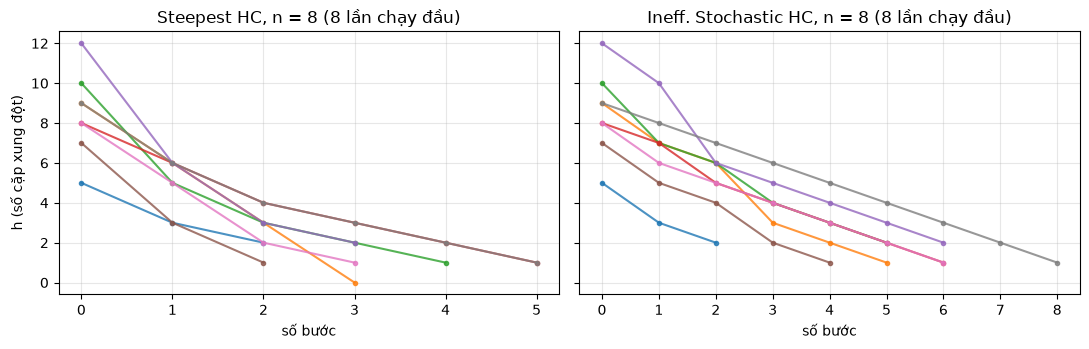

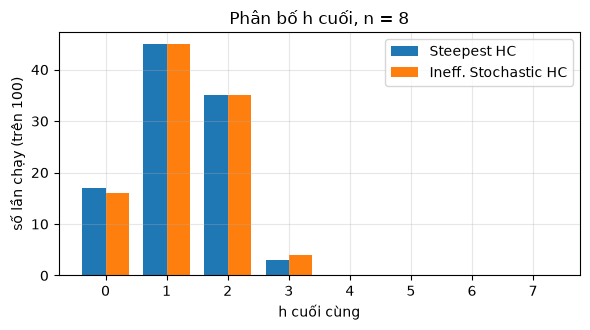

In [16]:
# đồ thị h theo số bước cho 5 lần chạy đầu của mỗi thuật toán (n = 8)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, name in zip(axs, ('Steepest HC', 'Ineff. Stochastic HC')):
    for r in RES_HC[(8, name)][:8]:
        ax.plot(r['hist'], marker='o', ms=3, alpha=.8)
    ax.set_title(f"{name}, n = 8 (8 lần chạy đầu)"); ax.set_xlabel("số bước"); ax.grid(alpha=.3)
axs[0].set_ylabel("h (số cặp xung đột)")
plt.tight_layout(); plt.savefig('figs/fig7_hc_hoi_tu.png', dpi=150, bbox_inches='tight'); plt.show()

# phân bố h cuối (n = 8)
fig, ax = plt.subplots(figsize=(6, 3.4))
w = .38
for k, name in enumerate(('Steepest HC', 'Ineff. Stochastic HC')):
    vals = [r['h'] for r in RES_HC[(8, name)]]
    ks = range(0, 8)
    ax.bar([x + (k - .5) * w for x in ks], [vals.count(x) for x in ks], width=w, label=name)
ax.set_xlabel("h cuối cùng"); ax.set_ylabel("số lần chạy (trên 100)"); ax.legend(); ax.grid(alpha=.3)
ax.set_title("Phân bố h cuối, n = 8")
plt.tight_layout(); plt.savefig('figs/fig8_hc_h_cuoi.png', dpi=150, bbox_inches='tight'); plt.show()

Ở hình trái/phải, h giảm rất nhanh trong 2–3 bước đầu rồi dừng (đường chấm kết thúc sớm), đúng với con số trung bình 3–5 bước. Biểu đồ cột cho thấy phần lớn các lượt không thành công dừng ở h = 1 hoặc h = 2, và Steepest có số lượt h = 0 nhỉnh hơn một chút.

__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

In [17]:
# Code and description go here

## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

In [18]:
# Code and description go here

## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

In [19]:
# Code and description go here

## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

In [20]:
# Code

### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

In [21]:
# Code and description go here

### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

In [22]:
# Code and description go here

## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

In [23]:
# Code and description go here

## Bảng ghi kết quả thí nghiệm (theo mẫu bảng 4.2 của đề)

Chỉ gồm các dòng được giao. Mỗi dòng chạy **100 lượt** từ 100 bàn cờ khởi tạo ngẫu nhiên khác nhau (cùng dãy bàn cờ cho các thuật toán cùng n). Tiêu chí dừng: h = 0, hoặc không còn nước đi làm giảm h (HC), hoặc hết 5000 vòng lặp (SA). "Xung đột" = h cuối cùng trung bình; "COUNT" = số lần gọi hàm mục tiêu `conflicts()` trung bình (không đồng nhất với COUNT của bài tô màu). Thời gian = trung bình mỗi lượt.

In [24]:
def simulated_annealing(board, T0=1.0, alpha=0.995, max_iter=5000):
    """SA tối thiểu (chỉ để điền dòng n = 4 của bảng; phần Task 5 sẽ làm đầy đủ ở Bài 7).
    Chọn ngẫu nhiên 1 láng giềng; nhận nếu tốt hơn, nếu tệ hơn nhận với xác suất exp(-dh/T); T = T0 * alpha^it."""
    board = np.array(board).copy(); n = len(board)
    cur = conflicts(board); evals = 1; steps = 0; hist = [cur]
    for it in range(max_iter):
        if cur == 0: break
        T = T0 * alpha ** it
        col = rng.randint(n); row = rng.randint(n - 1)
        if row >= board[col]: row += 1                       # hàng khác hàng hiện tại
        old = board[col]; board[col] = row
        h_new = conflicts(board); evals += 1
        dh = h_new - cur
        if dh <= 0 or rng.rand() < np.exp(-dh / T):
            cur = h_new; steps += 1
        else:
            board[col] = old
        hist.append(cur)
    return {'board': board, 'h': cur, 'steps': steps, 'evals': evals, 'hist': hist, 'stuck': cur > 0}

res_sa4 = run_many(simulated_annealing, 4, runs=100, seed=104)
s_sa4 = summarize(res_sa4)
print({k: round(float(v), 4) for k, v in s_sa4.items()})

{'runs': 100.0, 'success_%': 100.0, 'avg_final_h': 0.0, 'avg_steps': 24.38, 'avg_evals': 48.21, 'avg_time_s': 0.0005, 'stuck_runs': 0.0}


In [25]:
# ---- Bảng ghi kết quả thí nghiệm (các dòng được giao) ----
def row(n, name, s, res):
    return {'Bài toán': 'n-Queens', 'Kích thước': f'n = {n}', 'Thuật toán': name, 'Số màu / lượt': '100 lượt',
            'Thành công (%)': f"{s['success_%']:.0f}",
            'Xung đột / COUNT': f"h cuối TB = {s['avg_final_h']:.2f}; số lần đánh giá TB = {s['avg_evals']:.0f}",
            'Thời gian (s)': f"{s['avg_time_s']:.4f}"}
final = [row(4, 'Simulated Annealing', s_sa4, res_sa4)]
for name in ('Steepest HC', 'Ineff. Stochastic HC'):
    final.append(row(8, name, summarize(RES_HC[(8, name)]), RES_HC[(8, name)]))
df_final = pd.DataFrame(final)
print(df_final.to_string(index=False))
df_hc.to_csv('results/hc_summary.csv', index=False)
df_final.to_csv('results/bang_ket_qua.csv', index=False)
json.dump({'hc': df_hc.round(6).to_dict('records'), 'sa4': {k: float(v) for k, v in s_sa4.items()}}, open('results/hc_results.json', 'w'), indent=1)

Bài toán Kích thước           Thuật toán Số màu / lượt Thành công (%)                           Xung đột / COUNT Thời gian (s)
n-Queens      n = 4  Simulated Annealing      100 lượt            100  h cuối TB = 0.00; số lần đánh giá TB = 48        0.0005
n-Queens      n = 8          Steepest HC      100 lượt             17 h cuối TB = 1.24; số lần đánh giá TB = 235        0.0021
n-Queens      n = 8 Ineff. Stochastic HC      100 lượt             16 h cuối TB = 1.27; số lần đánh giá TB = 327        0.0029


**Nhận xét bảng.** Simulated Annealing (cấu hình tối thiểu T₀ = 1, α = 0,995, tối đa 5000 vòng) thành công 100/100 ở n = 4 với khoảng 48 lần đánh giá, nhờ chấp nhận nước đi tệ hơn để thoát cực trị cục bộ; trong khi ở n = 4 hai biến thể Hill Climbing chỉ đạt 41 % và 27 % (bảng phía trên). Ở n = 8, cả Steepest và Inefficient Stochastic đều chỉ thành công khoảng 1/6 số lượt. Dòng SA ở đây chỉ để điền bảng; việc khảo sát lịch làm nguội (Task 5) thuộc Bài 7.

## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [26]:
# Code and description go here